In [1]:
## Gotta turn this into a more proper looking script at some point.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os
import random

In [3]:
import re
from pathlib import Path
from datetime import datetime
from typing import Optional, Tuple, List

TOL = 1e-6  # float comparison tolerance
_TS_RE = re.compile(r'(\d{4}-\d{2}-\d{2})_(\d{6})$')

def parse_run_dt(name: str) -> Optional[datetime]:
    """
    Extract run timestamp from directory name.

    Handles names like:
      - '2025-09-19_170029'
      - 'HSIUM-126-2025-09-19_170029'

    Returns a datetime object, or None if parsing fails.
    """
    m = _TS_RE.search(name)
    if not m:
        return None

    date_str, time_str = m.groups()
    try:
        return datetime.strptime(f"{date_str}_{time_str}", "%Y-%m-%d_%H%M%S")
    except ValueError:
        return None

def read_metadata(run_dir: Path) -> Tuple[Optional[float], Optional[float]]:
    """
    Parse README.md assuming fixed lines like:
      - bottomLight : 100.0
      - exposure : 23.5
    Returns (bottom_light, exposure) as floats (or None if missing/unparseable).
    """
    readme = run_dir / "README.md"
    if not readme.exists():
        print(f"{run_dir}: ReadMe doesn't exist")
        return None, None

    bottom_light = None
    exposure = None

    try:
        with readme.open("r", errors="ignore") as f:
            for raw in f:
                line = raw.strip()
                # Normalize the leading dash and spaces
                if line.startswith("- "):
                    key_val = line[2:]  # drop "- "
                else:
                    key_val = line

                if key_val.lower().startswith("bottomlight"):
                    # split on first ":" only
                    parts = key_val.split(":", 1)
                    if len(parts) == 2:
                        try:
                            bottom_light = float(parts[1].strip())
                        except ValueError:
                            pass

                elif key_val.lower().startswith("exposure"):
                    parts = key_val.split(":", 1)
                    if len(parts) == 2:
                        try:
                            exposure = float(parts[1].strip())
                        except ValueError:
                            pass
    except Exception:
        return None, None

    #print(f"ReadMe checks: {run_dir}\n Bottom Light:{bottom_light}, Exposure: {exposure}")

    return bottom_light, exposure

def choose_best_run(section_dir: Path, cutoff: Optional[datetime] = None) -> Optional[Path]:
    """
    Pick ONE run dir for a section using:
      1) bottomLight == 100.0 preferred
      2) among those, highest exposure
      3) tie-break: newest timestamp
      4) if none with bottom==100, pick highest exposure; else newest
    Respects optional `cutoff` (run timestamp must be >= cutoff).
    """
    candidates: List[dict] = []

    for run_dir in section_dir.iterdir():
        if not run_dir.is_dir():
            continue
        dt = parse_run_dt(run_dir.name)
        if not dt:
            continue
        if cutoff and dt < cutoff:
            continue

        #print(f"Before ReadMe checks: {run_dir}\n")

        bottom, exposure = read_metadata(run_dir)
        #print(f"After ReadMe checks: {run_dir}\n Bottom Light:{bottom}, Exposure: {exposure}")
        candidates.append({
            "path": run_dir,
            "dt": dt,
            "bottom": bottom,
            "exposure": exposure,
            "has_bottom_100": (bottom is not None and abs(bottom - 100.0) < TOL),
            "has_exposure": (exposure is not None),
        })

    #print(f"Candidates:\n {candidates}")

    if not candidates:
        return None

    # Prefer pool: bottomLight==100.0, otherwise all
    pool = [c for c in candidates if c["has_bottom_100"]] or candidates
    #print(f"Pool:\n {pool}")

    # Sort:
    #   - first by whether exposure exists (True before False)
    #   - then by exposure value (descending; None treated as -inf)
    #   - then by datetime (ascending, so take last or invert sign)
    def key(c):
        exp_val = c["exposure"] if c["exposure"] is not None else float("-inf")
        return (c["has_exposure"], exp_val, c["dt"])

    # We want highest exposure and newest, so sort ascending by key and take the last
    pool.sort(key=key)
    return pool[-1]["path"]

In [4]:
BASE = Path("/data/icecores/Output/AL/DIC1/DIC1/")

# --- define date cutoff ---
CUTOFF = datetime(2025, 11, 9, 5, 0, 0) # CUTOFF = None to disable

csv_files = []
full_bubble_csv_files = []
for section_dir in sorted(p for p in BASE.iterdir() if p.is_dir() and p.name.startswith("DIC1-")):
    best = choose_best_run(section_dir, cutoff=CUTOFF)
    # if "ALHIC2302-51_2" in str(best):
    #         best = None
    # if "ALHIC2302-40" in str(best):
    #         best = None
    print(f"{section_dir} \nBest: {best}")
    if not best:
        print("Not Best")
        continue
    csv = next(iter(sorted(best.glob("*bubbles_per_cm.csv"))), None)
    full_bubble_csv = next(iter(sorted(best.glob("*bubbleData.csv"))), None)
    if csv:
        csv_files.append(csv)
    else:
        print("No CSV")
    if full_bubble_csv:
        full_bubble_csv_files.append(full_bubble_csv)
    else:
        print("No full bubble CSV")

/data/icecores/Output/AL/DIC1/DIC1/DIC1-142 
Best: /data/icecores/Output/AL/DIC1/DIC1/DIC1-142/HSIUM-732-2025-11-17_115800
/data/icecores/Output/AL/DIC1/DIC1/DIC1-150 
Best: /data/icecores/Output/AL/DIC1/DIC1/DIC1-150/HSIUM-728-2025-11-17_115800
/data/icecores/Output/AL/DIC1/DIC1/DIC1-151 
Best: /data/icecores/Output/AL/DIC1/DIC1/DIC1-151/HSIUM-724-2025-11-17_115800
/data/icecores/Output/AL/DIC1/DIC1/DIC1-152 
Best: /data/icecores/Output/AL/DIC1/DIC1/DIC1-152/HSIUM-720-2025-11-17_115800
/data/icecores/Output/AL/DIC1/DIC1/DIC1-153 
Best: /data/icecores/Output/AL/DIC1/DIC1/DIC1-153/HSIUM-716-2025-11-17_115800
/data/icecores/Output/AL/DIC1/DIC1/DIC1-154 
Best: /data/icecores/Output/AL/DIC1/DIC1/DIC1-154/HSIUM-712-2025-11-17_115800
/data/icecores/Output/AL/DIC1/DIC1/DIC1-155 
Best: /data/icecores/Output/AL/DIC1/DIC1/DIC1-155/HSIUM-708-2025-11-17_115800
/data/icecores/Output/AL/DIC1/DIC1/DIC1-156 
Best: /data/icecores/Output/AL/DIC1/DIC1/DIC1-156/HSIUM-703-2025-11-17_115800
/data/icecores/O

In [5]:
print(csv_files)

[PosixPath('/data/icecores/Output/AL/DIC1/DIC1/DIC1-142/HSIUM-732-2025-11-17_115800/DIC1-142bubbles_per_cm.csv'), PosixPath('/data/icecores/Output/AL/DIC1/DIC1/DIC1-150/HSIUM-728-2025-11-17_115800/DIC1-150bubbles_per_cm.csv'), PosixPath('/data/icecores/Output/AL/DIC1/DIC1/DIC1-151/HSIUM-724-2025-11-17_115800/DIC1-151bubbles_per_cm.csv'), PosixPath('/data/icecores/Output/AL/DIC1/DIC1/DIC1-152/HSIUM-720-2025-11-17_115800/DIC1-152bubbles_per_cm.csv'), PosixPath('/data/icecores/Output/AL/DIC1/DIC1/DIC1-153/HSIUM-716-2025-11-17_115800/DIC1-153bubbles_per_cm.csv'), PosixPath('/data/icecores/Output/AL/DIC1/DIC1/DIC1-154/HSIUM-712-2025-11-17_115800/DIC1-154bubbles_per_cm.csv'), PosixPath('/data/icecores/Output/AL/DIC1/DIC1/DIC1-155/HSIUM-708-2025-11-17_115800/DIC1-155bubbles_per_cm.csv'), PosixPath('/data/icecores/Output/AL/DIC1/DIC1/DIC1-156/HSIUM-703-2025-11-17_115800/DIC1-156bubbles_per_cm.csv'), PosixPath('/data/icecores/Output/AL/DIC1/DIC1/DIC1-157/HSIUM-698-2025-11-17_115800/DIC1-157bubb

In [6]:
all_data = []
for file in csv_files:
    df = pd.read_csv(file)
    all_data.append(df)
    
timestamp = datetime.now().strftime("%Y-%m-%d_%H%M%S")

# === Combine and sort all data === 
combined_df = pd.concat(all_data, ignore_index=True)
combined_df = combined_df.sort_values(by=["Depth_cm"]).reset_index(drop=True)
combined_df = combined_df[combined_df["Depth_cm"] >= 1000]

output_dir = Path(f"/data/icecores/Output/AL/DIC1/DIC1/FullCoreData/{timestamp}")
output_dir.mkdir(parents=True, exist_ok=False) 
combined_df.to_csv(f"{output_dir}/combinedBubbles.csv", index=False)
print("Output Dir: ", output_dir)

full_bubble_data = []
for file in full_bubble_csv_files:
    df = pd.read_csv(file)
    full_bubble_data.append(df)

# === Combine and sort all data === 
full_bubble_df = pd.concat(full_bubble_data, ignore_index=True)
full_bubble_df = full_bubble_df.sort_values(by=["depth_cm"]).reset_index(drop=True)
full_bubble_df = full_bubble_df[full_bubble_df["depth_cm"] >= 1000]
output_dir = Path(f"/data/icecores/Output/AL/DIC1/DIC1/FullCoreData/{timestamp}")
full_bubble_df.to_csv(f"{output_dir}/full_bubble.csv", index=False)
print("Output Dir: ", output_dir)

Output Dir:  /data/icecores/Output/AL/DIC1/DIC1/FullCoreData/2025-11-18_110021


/tmp/ipykernel_765767/2218031627.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined_df = pd.concat(all_data, ignore_index=True)


Output Dir:  /data/icecores/Output/AL/DIC1/DIC1/FullCoreData/2025-11-18_110021



Fixing outliers in 'Bubble_Count' using rolling median (window=5, threshold=3.0):


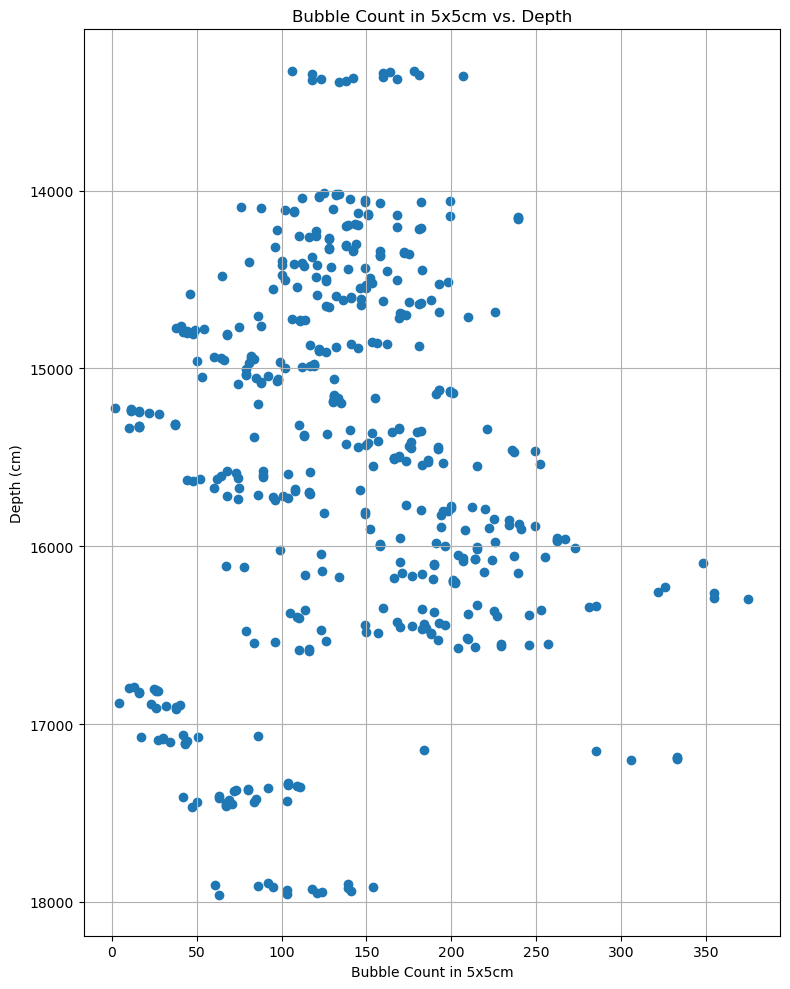


Fixing outliers in 'Avg_Orientation' using rolling median (window=5, threshold=3.0):


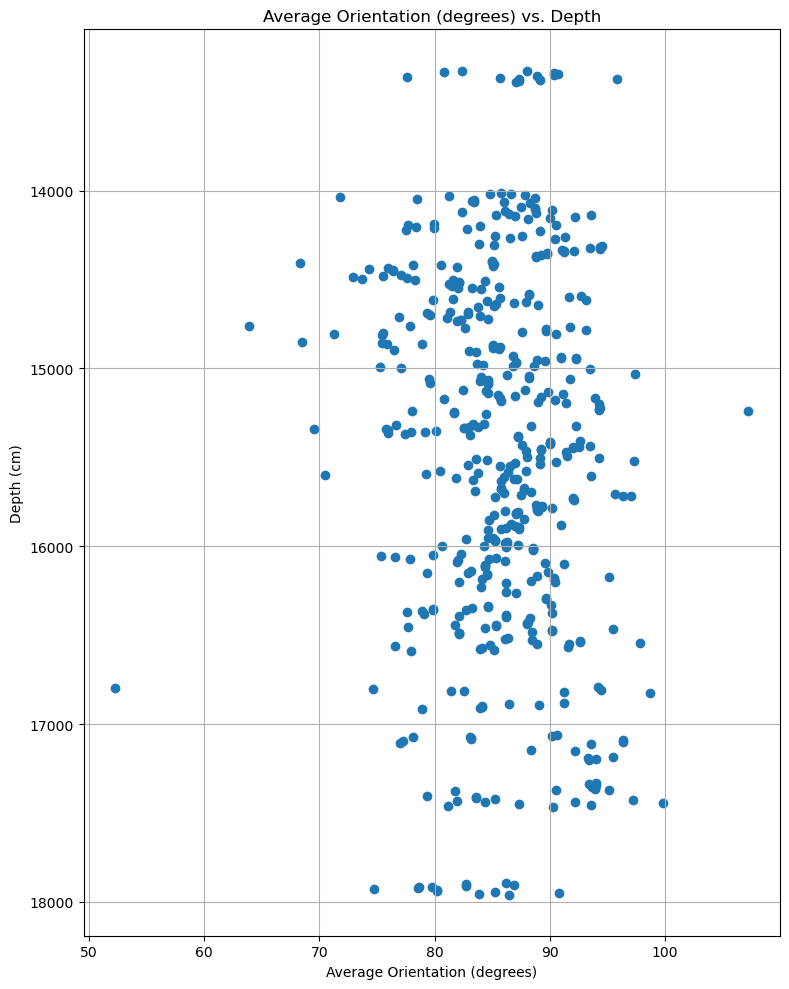


Fixing outliers in 'Avg_Elongation' using rolling median (window=5, threshold=3.0):


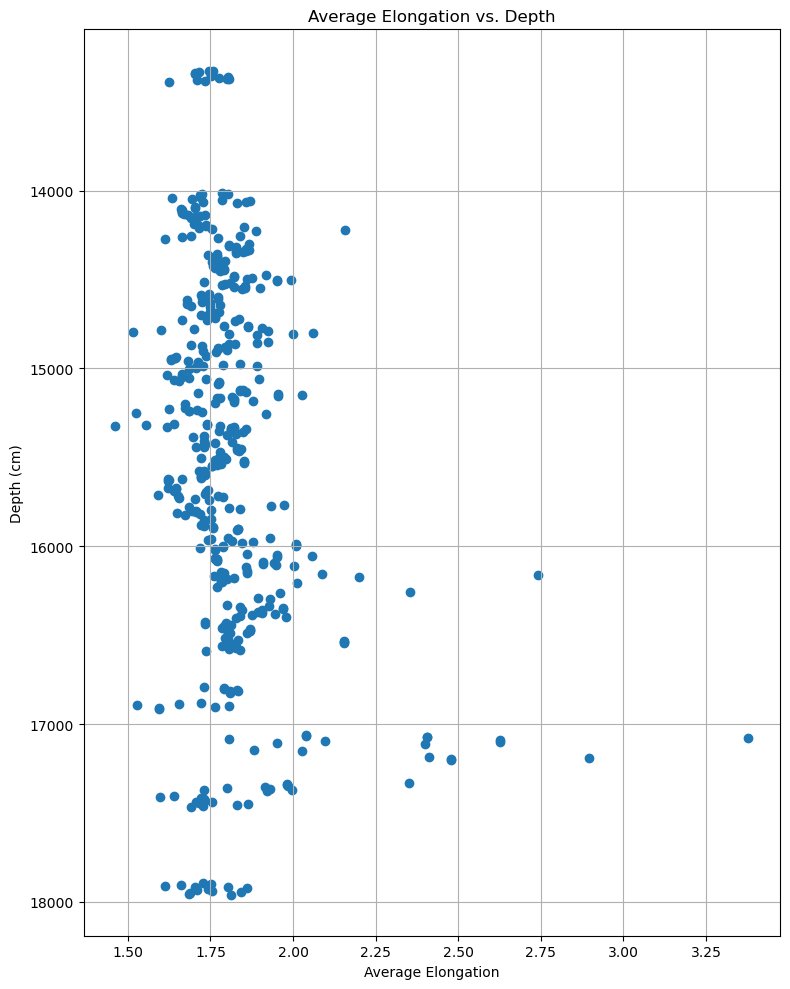

In [7]:
def smooth_outliers_rolling(df: pd.DataFrame, column: str, window: int = 5, threshold: float = 3.0) -> pd.Series:
    series = df[column]
    rolling_median = series.rolling(window=window, center=True).median()
    
    # Calculate deviation from rolling median
    deviation = (series - rolling_median).abs()
    mad = deviation.rolling(window=window, center=True).median()  # Median Absolute Deviation
    
    # Flag outliers: values farther than threshold * MAD from the rolling median
    outliers = deviation > (threshold * mad)
    
    if outliers.any():
        print(f"\nFixing outliers in '{column}' using rolling median (window={window}, threshold={threshold}):")
        #print(df.loc[outliers, ["Depth_cm", column]].to_string(index=False))
    
    # Replace outliers with rolling median values
    fixed_series = series.copy()
    fixed_series[outliers] = rolling_median[outliers]
    
    return fixed_series

file = f"{output_dir}/combinedBubbles.csv"
combined_df = pd.read_csv(file)

# === Define variables to plot ===
plot_vars = [
    ("Bubble_Count", "Bubble Count in 5x5cm"),
    ("Avg_Orientation", "Average Orientation (degrees)"),
    ("Avg_Elongation", "Average Elongation")
]

# === Plot each variable vs depth (depth on y-axis) ===
for var, label in plot_vars:
    combined_df[var] = smooth_outliers_rolling(combined_df, var, window=5, threshold=3.0)

    plt.figure(figsize=(8, 10))
    plt.scatter(combined_df[var], combined_df["Depth_cm"])

    plt.xlabel(label)
    plt.ylabel("Depth (cm)")
    plt.title(f"{label} vs. Depth")
    plt.gca().invert_yaxis()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{output_dir}/{var}bubbleGraph.png", dpi=300, bbox_inches='tight')
    plt.show()

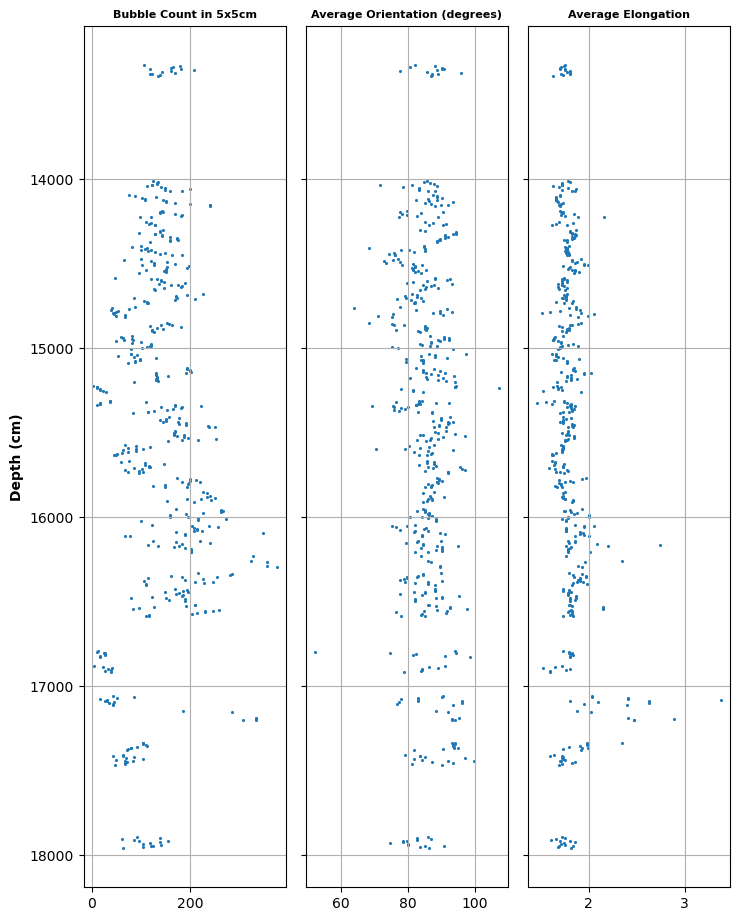

In [8]:
# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleGraph.png", dpi=300, bbox_inches='tight')
plt.show()

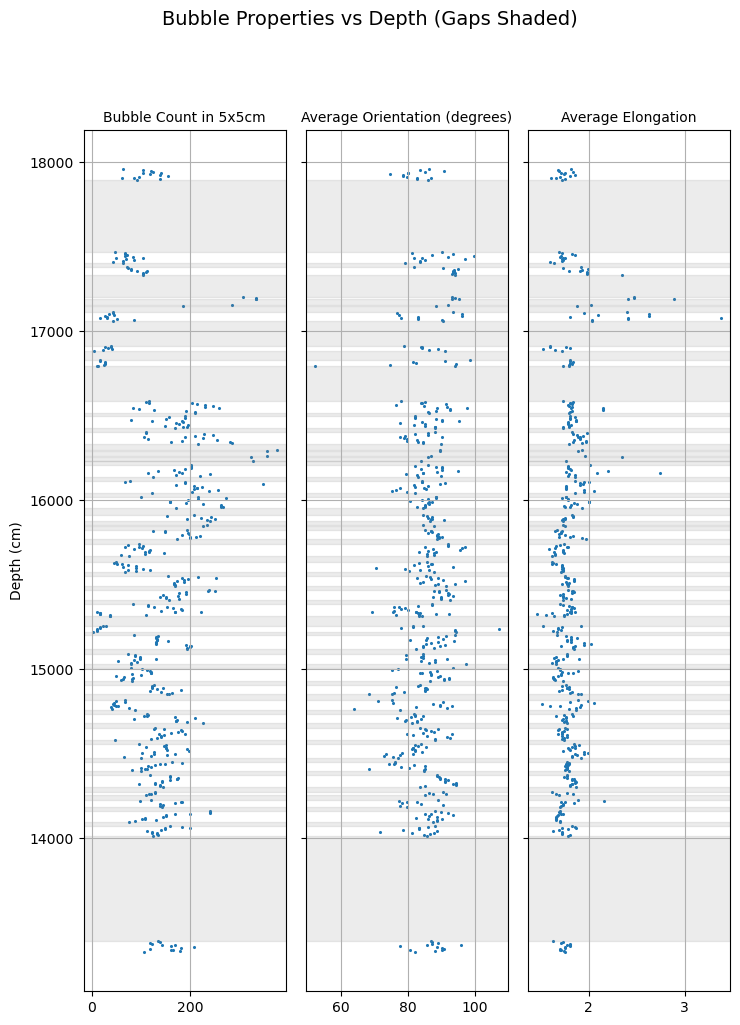

In [9]:
combined_df["Depth_Diff"] = combined_df["Depth_cm"].diff()

gap_threshold = 10
gap_mask = combined_df["Depth_Diff"] > gap_threshold
gap_indices = combined_df.index[gap_mask].tolist()

# --- Get depth ranges for each gap ---
gap_ranges = []
for idx in gap_indices:
    start = combined_df.loc[idx - 1, "Depth_cm"]
    end = combined_df.loc[idx, "Depth_cm"]
    gap_ranges.append((start, end))

# Drop helper column
combined_df = combined_df.drop(columns="Depth_Diff")

# --- Plot the data with gap shading ---
fig, axes = plt.subplots(nrows=1, ncols=len(plot_vars), figsize=(2.5 * len(plot_vars), 10), sharey=True)

for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=10)
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

    # Shade gaps
    for start, end in gap_ranges:
        ax.axhspan(start, end, color='gray', alpha=0.15)

# Add shared y-label
axes[0].set_ylabel("Depth (cm)")
axes[0].invert_yaxis()

plt.tight_layout()
plt.suptitle("Bubble Properties vs Depth (Gaps Shaded)", y=1.02, fontsize=14)
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleGraph_GapsShaded.png", dpi=300, bbox_inches='tight')
plt.show()


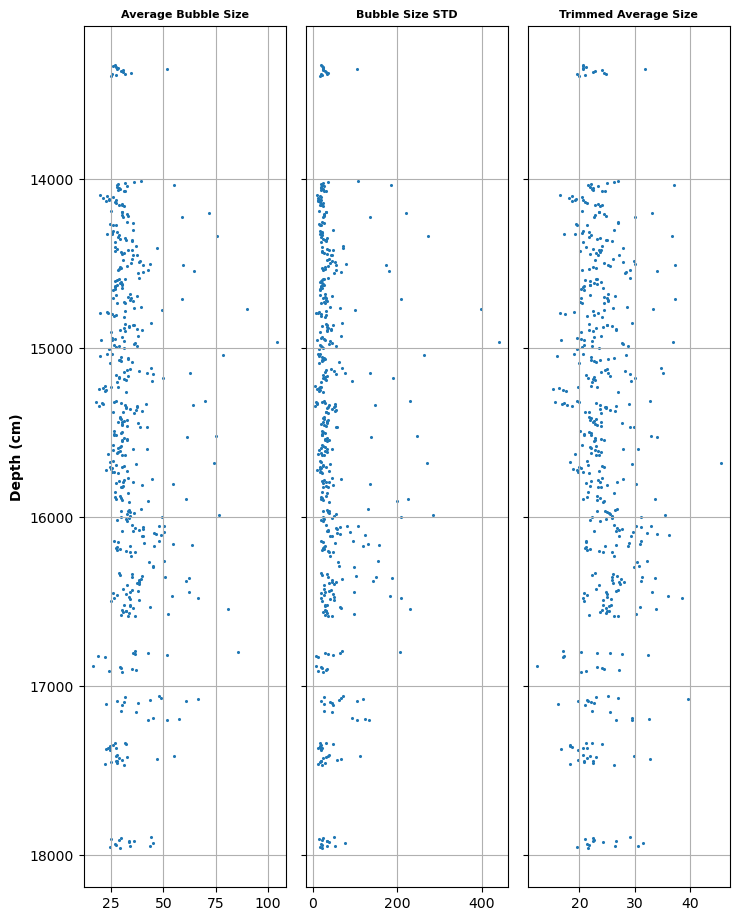

In [10]:
plot_vars = [
    ("Avg_Bubble_Size", "Average Bubble Size"),
    ("STD_Bubble_Size", "Bubble Size STD"),
    ("Trimmed_Mean_Bubble_Size", "Trimmed Average Size")
]

# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleSizeGraph.png", dpi=300, bbox_inches='tight')
plt.show()

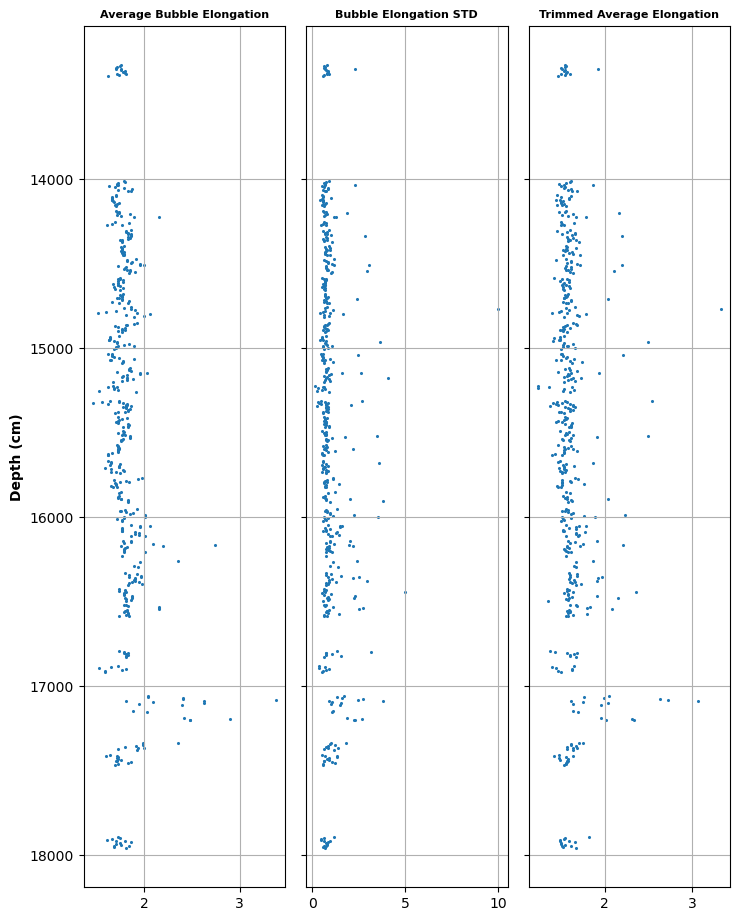

In [11]:
plot_vars = [
    ("Avg_Elongation", "Average Bubble Elongation"),
    ("STD_Elongation", "Bubble Elongation STD"),
    ("Trimmed_Mean_Elongation", "Trimmed Average Elongation")
]

# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleElongationGraph.png", dpi=300, bbox_inches='tight')
plt.show()

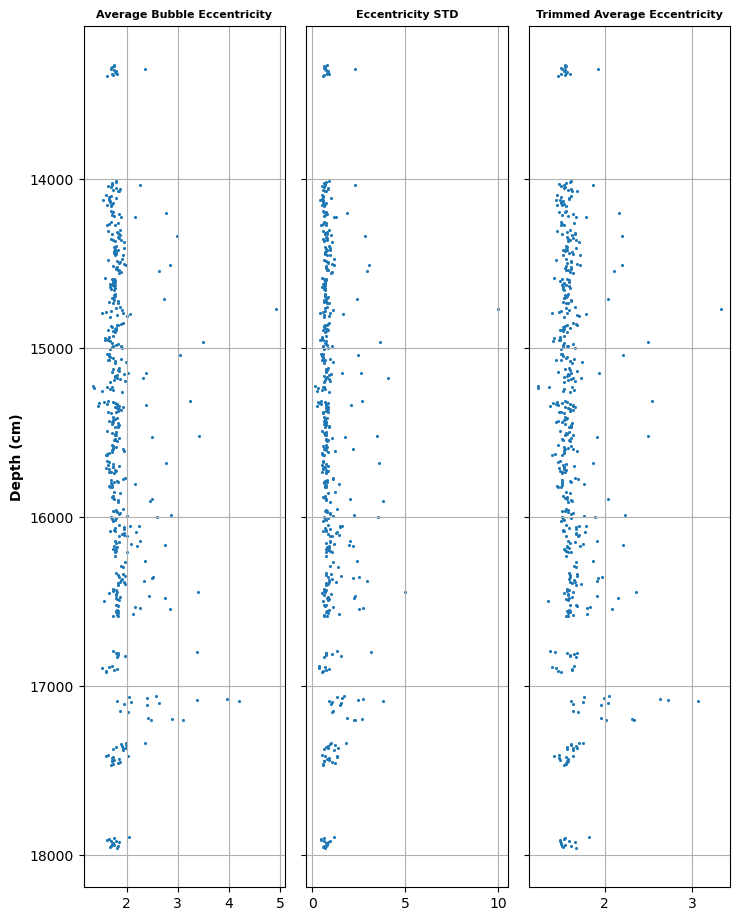

In [12]:
plot_vars = [
    ("Avg_Eccentricity", "Average Bubble Eccentricity"),
    ("STD_Eccentricity", "Eccentricity STD"),
    ("Trimmed_Mean_Eccentricity", "Trimmed Average Eccentricity")
]

# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleEccentricityGraph.png", dpi=300, bbox_inches='tight')
plt.show()

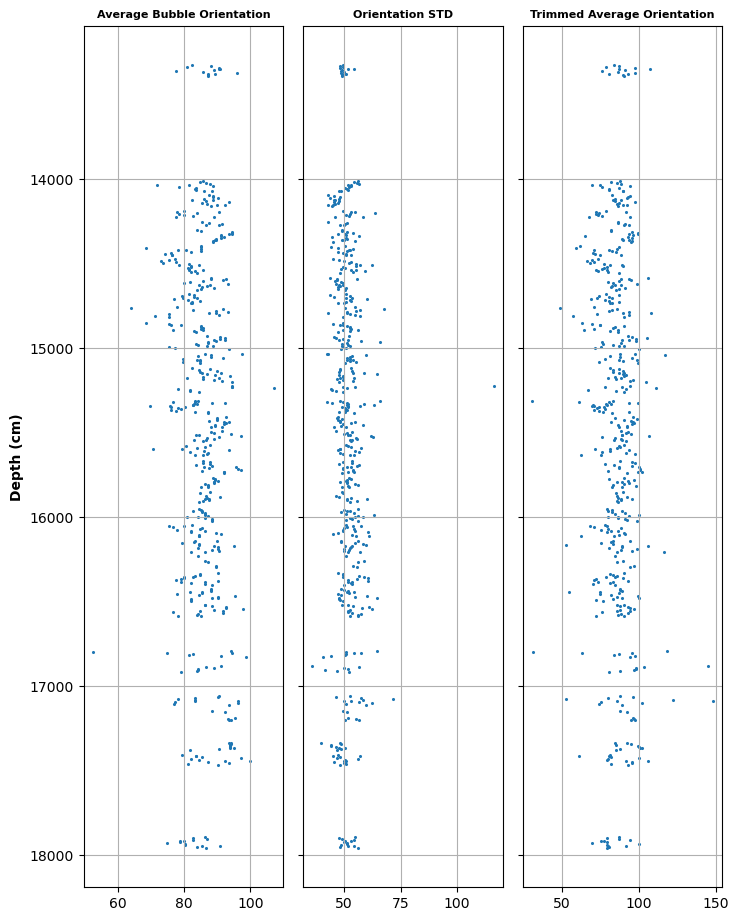

In [13]:
plot_vars = [
    ("Avg_Orientation", "Average Bubble Orientation"),
    ("STD_Orientation", "Orientation STD"),
    ("Trimmed_Mean_Orientation", "Trimmed Average Orientation")
]

# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleOrientaionGraph.png", dpi=300, bbox_inches='tight')
plt.show()

In [14]:
import numpy as np
import pandas as pd
import ruptures as rpt
import matplotlib.pyplot as plt

def _rolling_median_rows(x: np.ndarray, window_rows: int, min_count: int) -> np.ndarray:
    s = pd.Series(x)
    return s.rolling(window=window_rows, center=True, min_periods=min_count).median().to_numpy()

def overlay_median_line(ax, x_vals: np.ndarray, depths: np.ndarray):
    med = _rolling_median_rows(x_vals.astype(float), window_rows=10, min_count=5)
    mask = ~(np.isnan(med) | np.isnan(depths))
    if np.any(mask):
        ax.scatter(med[mask], depths[mask], c='red', s=4, label="Rolling median")

def detect_change_points(signal: np.ndarray, model: str = "rbf",
                         min_size: int = 5, jump: int = 10, pen_scale: float = 2.0):
    algo = rpt.Pelt(model=model, min_size=min_size, jump=jump).fit(signal)
    n = len(signal)
    pen = pen_scale * np.log(n if n > 1 else 2)
    cps = algo.predict(pen=pen)
    return cps[:-1]  # drop last (end marker)

def plot_bubble_cpd(df: pd.DataFrame, output_dir, include_orientation: bool = True):
    depth = df['Depth_cm'].values / 100
    

    panels = [
        ("Bubble Count", "Bubble_Count", 3.0, "Bubbles per cm²", None),
        ("Median Bubble Size", "Median_Bubble_Size", 2.0, "Pixels", "STD_Bubble_Size"),
        ("Median Bubble Elongation", "Median_Elongation", 2.0, "Pixels", "STD_Elongation")
    ]
    if include_orientation and ("Median_Orientation" in df.columns):
        panels.insert(3, ("Median Bubble Orientation", "Median_Orientation", 1.0, "Degrees", "STD_Orientation"))

    ncols = len(panels)
    fig, axes = plt.subplots(ncols=ncols, figsize=(5*ncols, 15), sharey=True)
    if ncols == 1:
        axes = [axes]  # normalize to iterable

    fig.suptitle("DIC1 - Bubble Properties by Depth", fontsize=18, fontweight='bold')

    for ax, (title, col, pen_scale, xLabel, std_col) in zip(axes, panels):
        signal = df[col].values.astype(float)
        cps = detect_change_points(signal, pen_scale=pen_scale)
        ax.scatter(signal, depth, s=4.5, label=title)
        # if std_col != None:
        #     std = df[std_col].values.astype(float)
        #     ax.scatter(signal, depth, s=4.5+std, facecolor=(1, 1, 1, 0), edgecolors=(0, 0, 0, 1), linewidths=2)
        overlay_median_line(ax, signal, depth)
        for i, cp in enumerate(cps):
            ax.axhline(y=depth[cp], color='r', linestyle='--',
                       label='Change Point' if i == 0 else None)
        ax.set_title(title, fontweight='bold',  fontsize=15)
        ax.set_xlabel(xLabel, fontsize=14)
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
        ax.tick_params(axis='x', labelsize=12)
        ax.invert_yaxis()
        ax.legend(fontsize=12)

    axes[0].set_ylabel("Depth (m)",  fontsize=14)
    axes[0].tick_params(axis='y', labelsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    if ncols == 4:
        ax.invert_yaxis()

    suffix = "" if include_orientation else "_no_orientation"
    out_path = output_dir / f"bubble_combinedMedOverlayCPD{suffix}.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

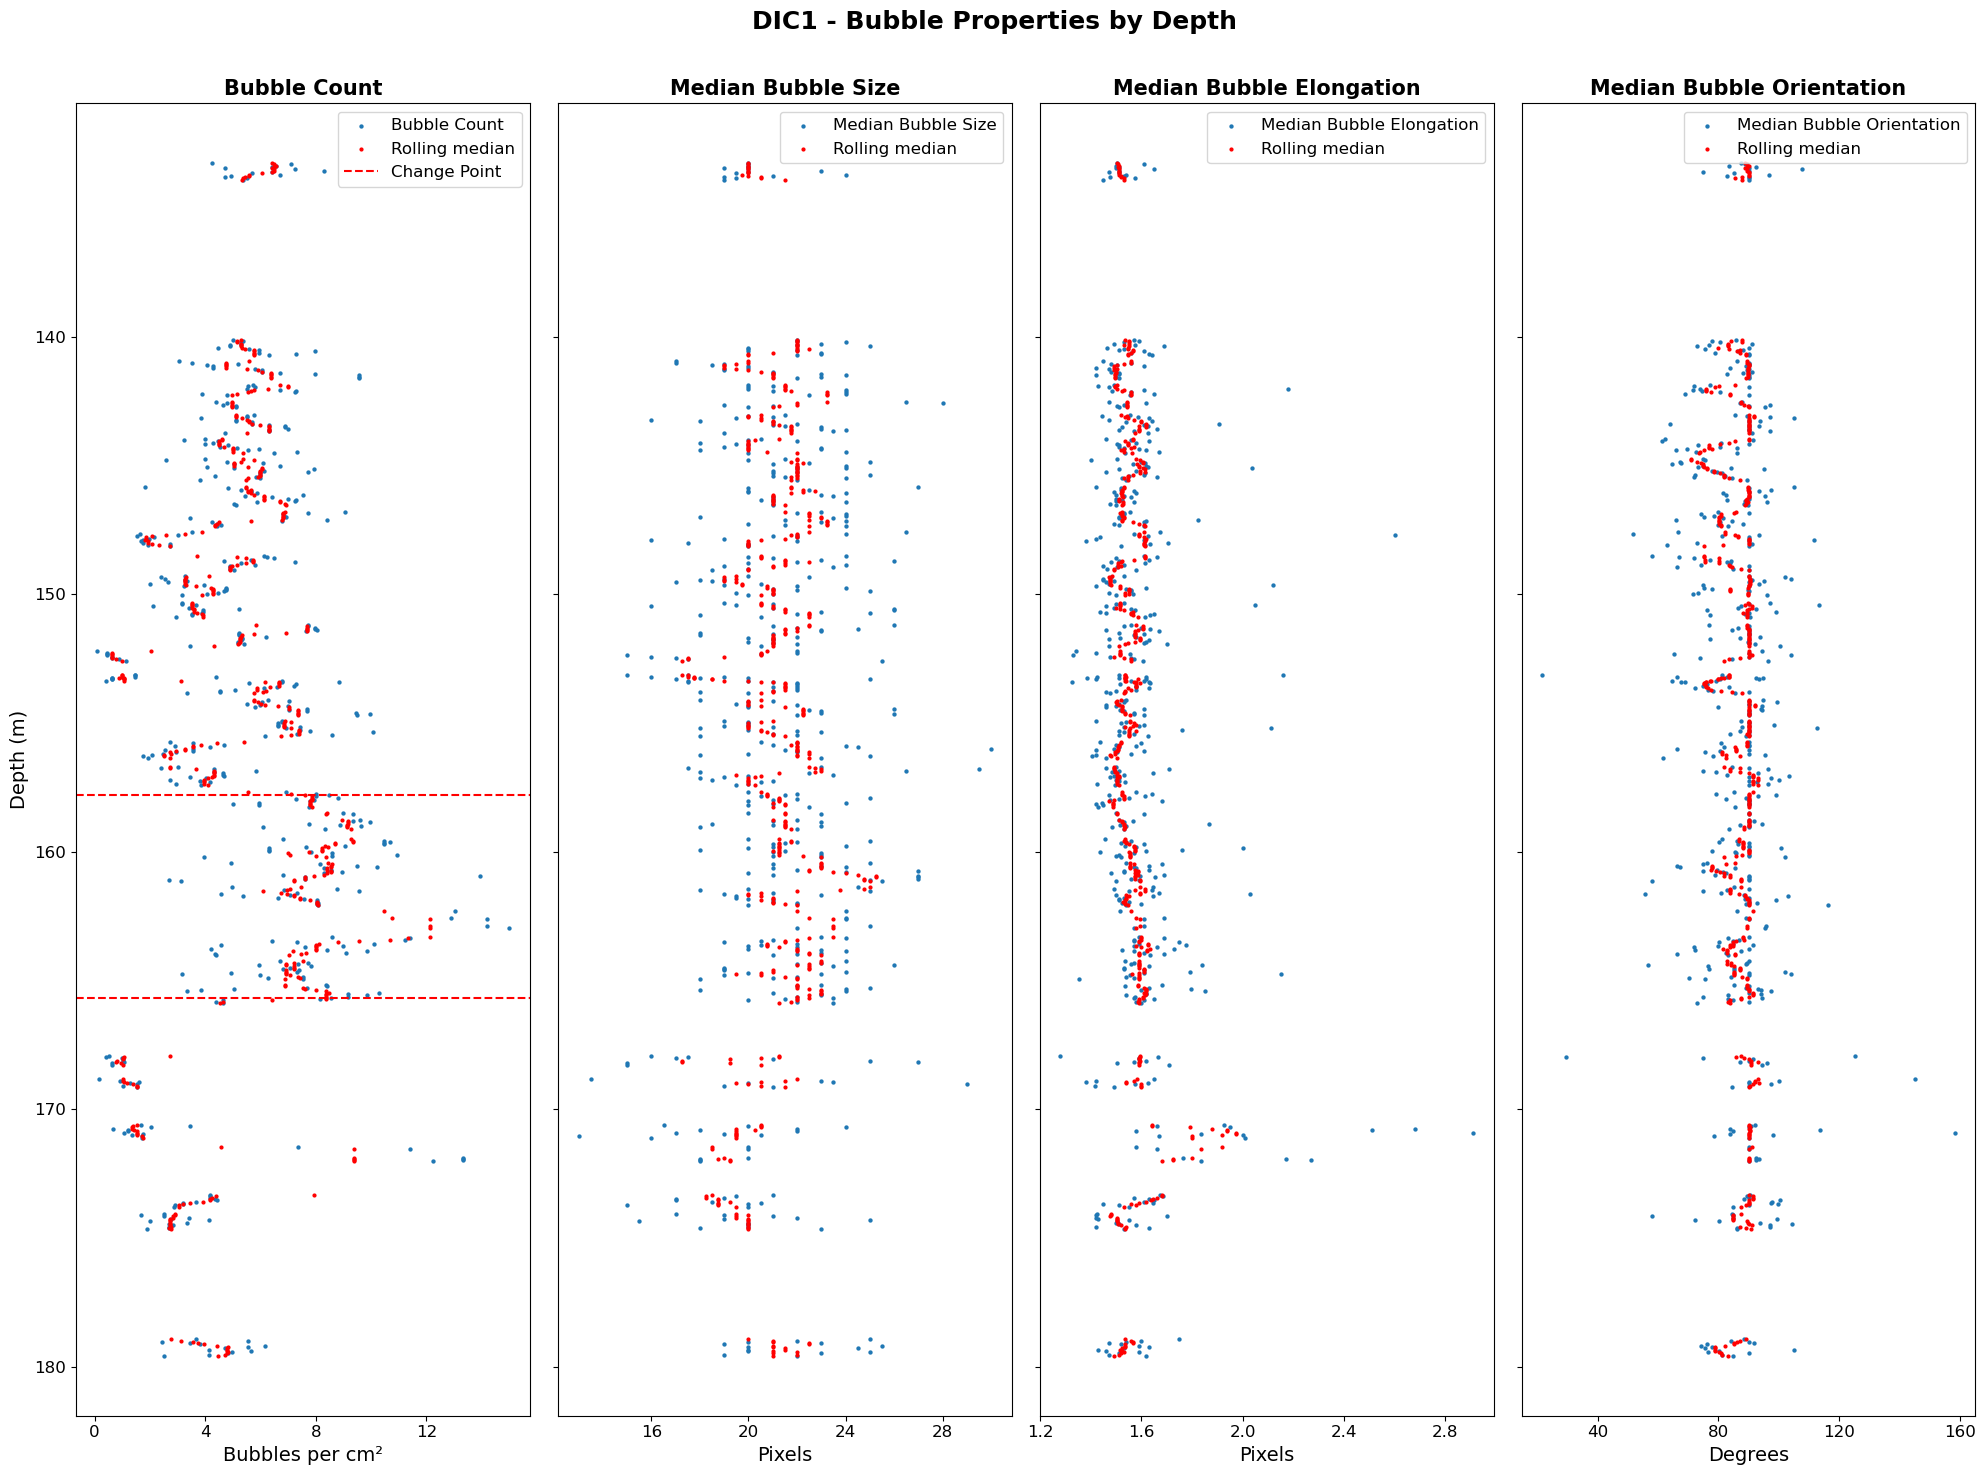

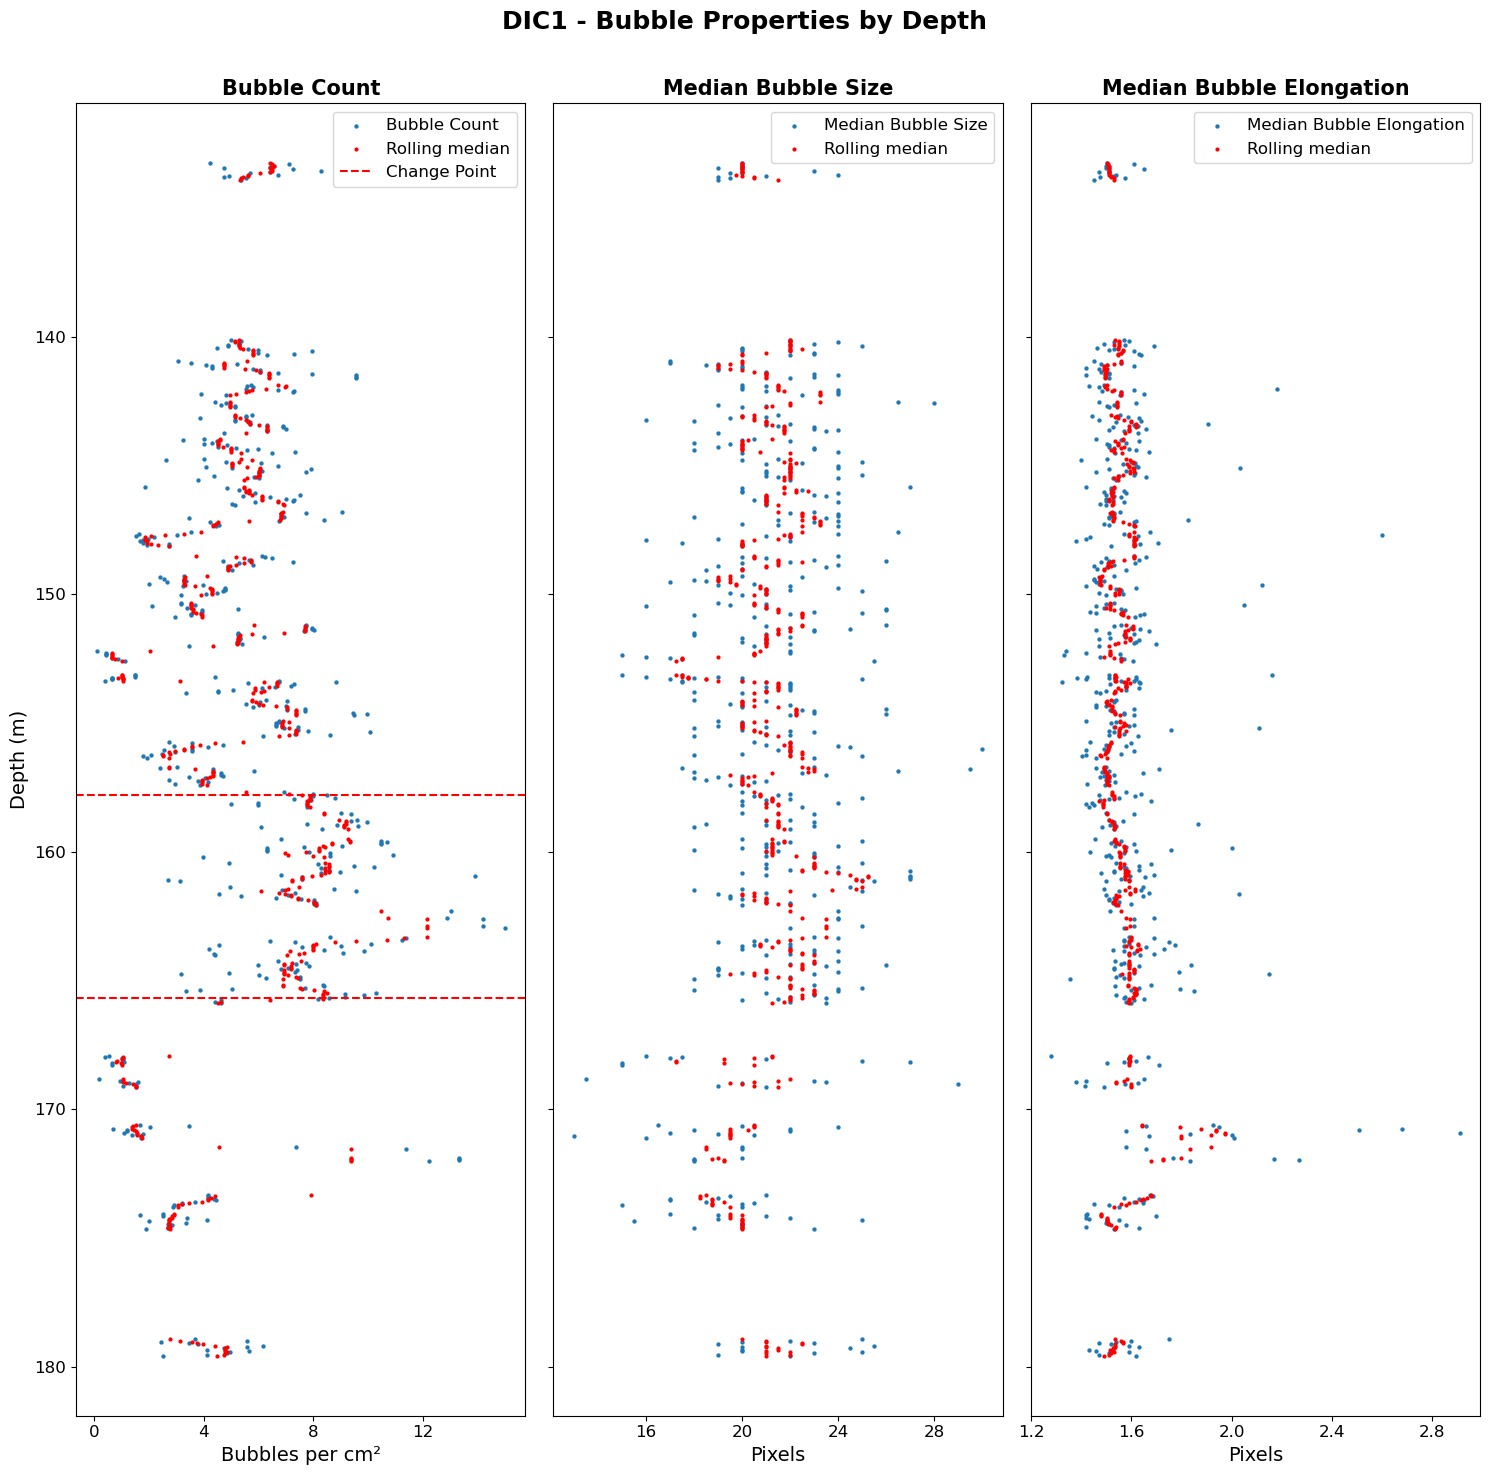

In [15]:
bubbles_df = combined_df.copy()
bubbles_df["Bubble_Count"] = bubbles_df['Bubble_Count'] / 25

plot_bubble_cpd(bubbles_df, output_dir)                  # includes orientation
plot_bubble_cpd(bubbles_df, output_dir, include_orientation=False)  # skips it

In [41]:
import numpy as np
import pandas as pd
import ruptures as rpt
import matplotlib.pyplot as plt

def _rolling_median_rows(x: np.ndarray, window_rows: int, min_count: int) -> np.ndarray:
    s = pd.Series(x)
    return s.rolling(window=window_rows, center=True, min_periods=min_count).median().to_numpy()

def overlay_median_line(ax, x_vals: np.ndarray, depths: np.ndarray):
    med = _rolling_median_rows(x_vals.astype(float), window_rows=10, min_count=5)
    mask = ~(np.isnan(med) | np.isnan(depths))
    if np.any(mask):
        ax.scatter(med[mask], depths[mask], c='red', s=4, label="Rolling median (window: 10)")

def detect_change_points(signal: np.ndarray, model: str = "rbf",
                         min_size: int = 5, jump: int = 10, pen_scale: float = 2.0):
    algo = rpt.Pelt(model=model, min_size=min_size, jump=jump).fit(signal)
    n = len(signal)
    pen = pen_scale * np.log(n if n > 1 else 2)
    cps = algo.predict(pen=pen)
    return cps[:-1]  # drop last (end marker)

def plot_avg_bubble_cpd(df: pd.DataFrame, output_dir, include_orientation: bool = True):
    depth = df['Depth_cm'].values / 100
    

    panels = [
        ("Bubble Count", "Bubble_Count", 3.0, "Bubbles per cm²", None),
        ("Average Bubble Size", "Avg_Bubble_Size", 2.0, "Pixels", "STD_Bubble_Size"),
        ("Average Bubble Elongation", "Avg_Elongation", 2.0, "Pixels", "STD_Elongation")
    ]
    if include_orientation and ("Avg_Orientation" in df.columns):
        panels.insert(3, ("Average Bubble Orientation", "Avg_Orientation", 1.0, "Degrees", "STD_Orientation"))

    ncols = len(panels)
    fig, axes = plt.subplots(ncols=ncols, figsize=(5*ncols, 15), sharey=True)
    if ncols == 1:
        axes = [axes]  # normalize to iterable

    fig.suptitle("DIC1 - Bubble Properties by Depth", fontsize=18, fontweight='bold')

    for ax, (title, col, pen_scale, xLabel, std_col) in zip(axes, panels):
        signal = df[col].values.astype(float)
        cps = detect_change_points(signal, pen_scale=pen_scale)
        ax.scatter(signal, depth, s=4.5, label=title)
        # if std_col != None:
        #     std = df[std_col].values.astype(float)
        #     ax.scatter(signal, depth, s=4.5+std, facecolor=(1, 1, 1, 0), edgecolors=(0, 0, 0, 1), linewidths=2)
        overlay_median_line(ax, signal, depth)
        for i, cp in enumerate(cps):
            ax.axhline(y=depth[cp], color='r', linestyle='--',
                       label='Change Point' if i == 0 else None)
        ax.set_title(title, fontweight='bold',  fontsize=15)
        ax.set_xlabel(xLabel, fontsize=14)
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
        ax.tick_params(axis='x', labelsize=12)
        ax.invert_yaxis()
        ax.legend(loc=1, fontsize=12)

    axes[0].set_ylabel("Depth (m)",  fontsize=14)
    axes[0].tick_params(axis='y', labelsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    if ncols == 4:
        ax.invert_yaxis()

    suffix = "" if include_orientation else "_no_orientation"
    out_path = output_dir / f"AvgBubble_combinedMedOverlayCPD{suffix}.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

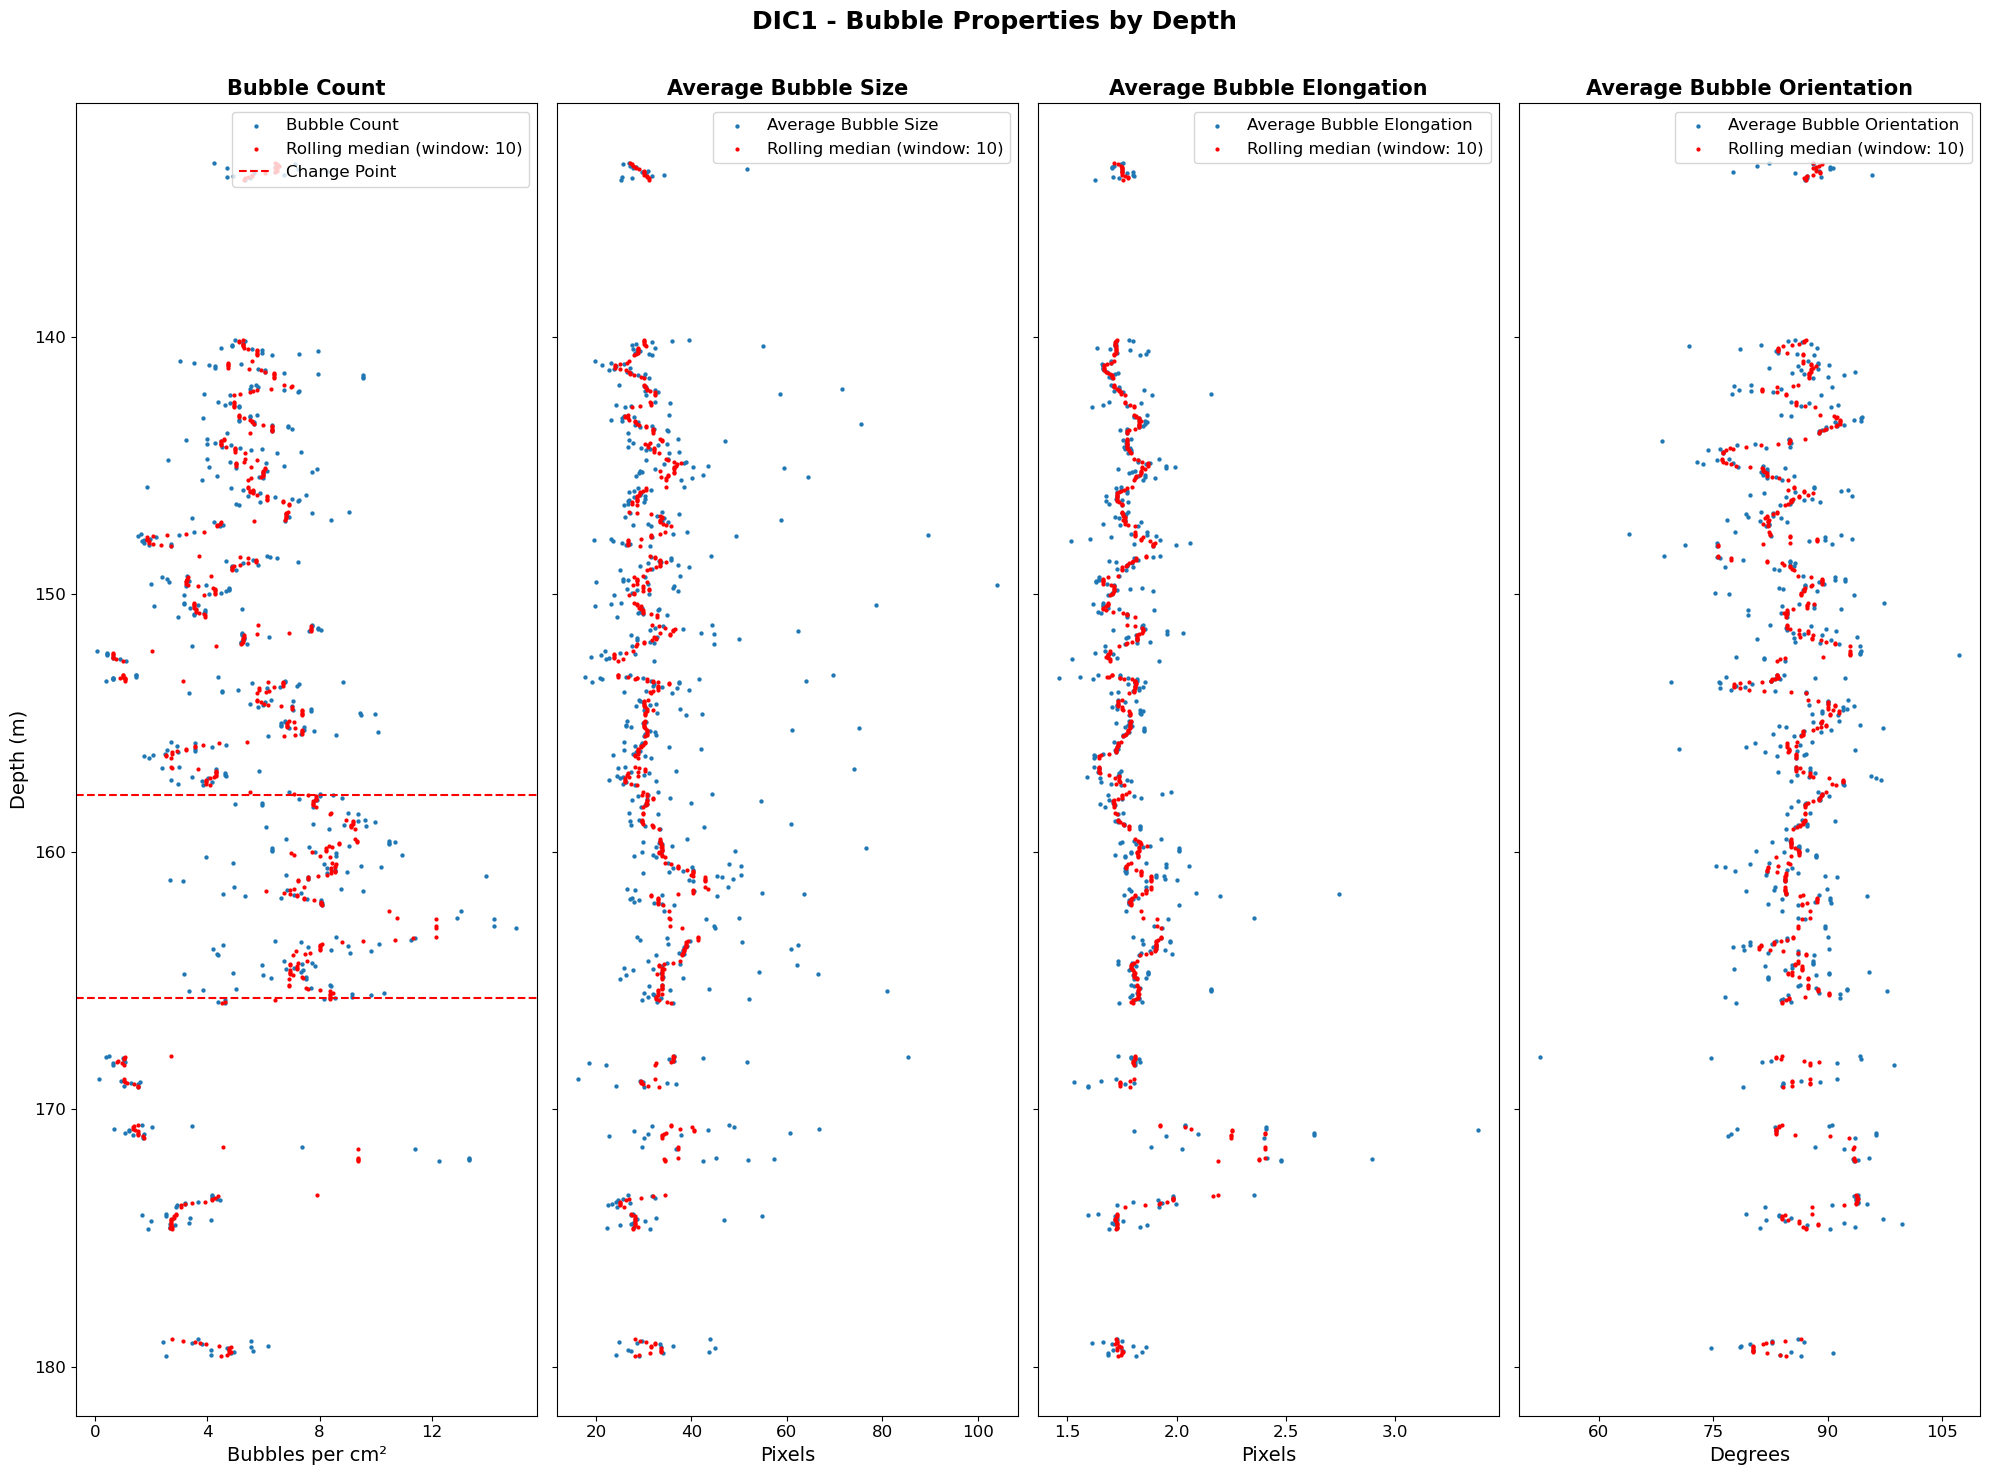

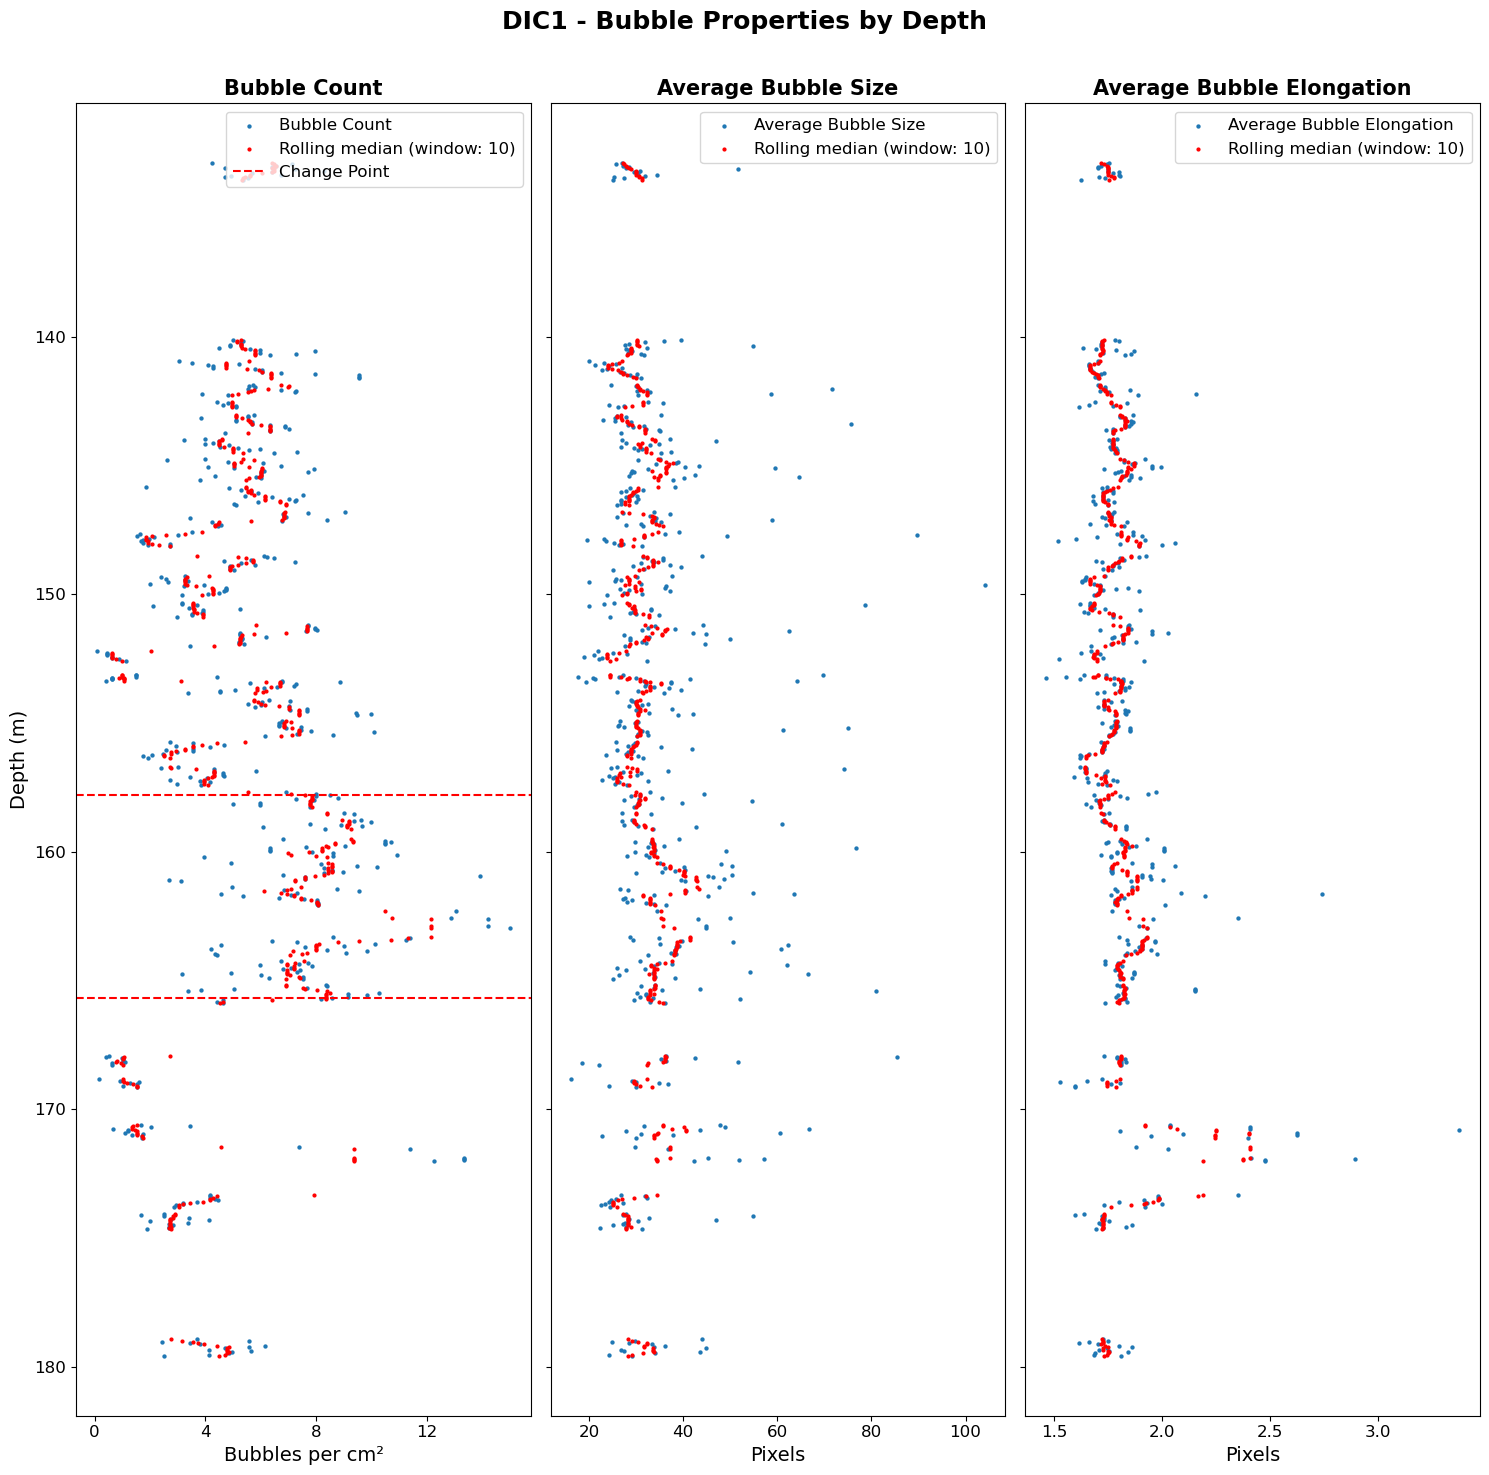

In [42]:
plot_avg_bubble_cpd(bubbles_df, output_dir)                  # includes orientation
plot_avg_bubble_cpd(bubbles_df, output_dir, include_orientation=False)  # skips it

Counts for each bin:
[7.3336e+04 2.3400e+02 4.3000e+01 2.1000e+01 7.0000e+00 1.0000e+01
 6.0000e+00 4.0000e+00 1.0000e+00 3.0000e+00]


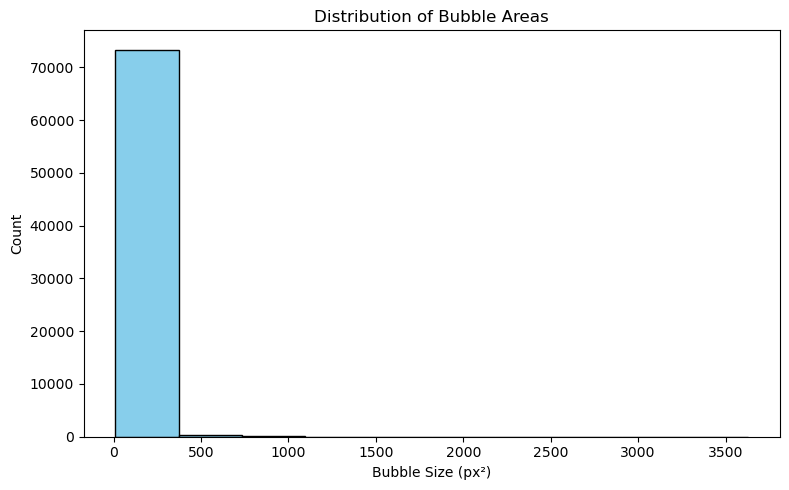

In [18]:
import numpy as np

#data = full_bubble_df["area"]
#print(filtered["area"])
#bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 10)
plt.figure(figsize=(8, 5))
counts, bin_edges, patches = plt.hist(full_bubble_df["area"], bins=10, color='skyblue', edgecolor='black')
print("Counts for each bin:")
print(counts)
plt.xlabel("Bubble Size (px²)")
plt.ylabel("Count")
plt.title("Distribution of Bubble Areas")
plt.tight_layout()
#plt.savefig(f"{output_dir}/TotalBubbleSizeHistogram.png", dpi=300, bbox_inches='tight')
plt.show()

Removed 6236 outliers
0        19.0
1        10.0
2        30.0
3        13.0
5        39.0
         ... 
73656    29.0
73657    13.0
73658    11.0
73659    33.0
73664    28.0
Name: area, Length: 67429, dtype: float64
Counts for each bin:
[25934. 12771.  8656.  5891.  4310.  3176.  2331.  1740.  1369.  1251.]


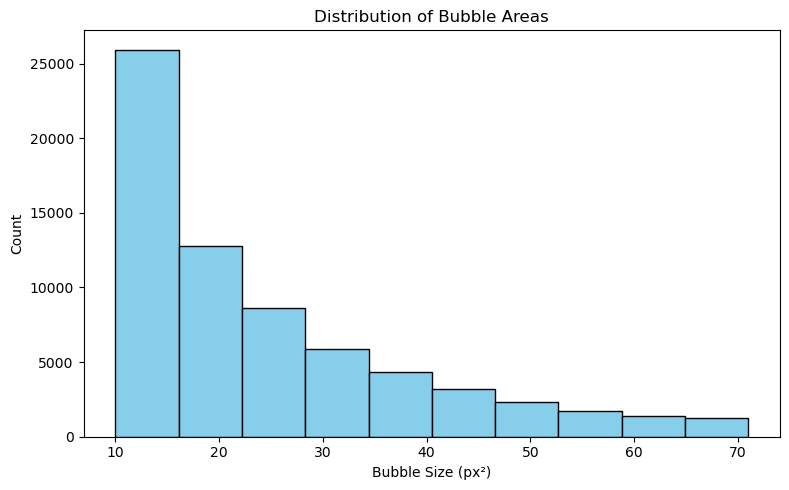

In [19]:
import numpy as np

Q1 = full_bubble_df["area"].quantile(0.25)
Q3 = full_bubble_df["area"].quantile(0.75)
IQR = Q3 - Q1

# Define threshold (1.5×IQR is standard, 3×IQR is stricter)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered = full_bubble_df[(full_bubble_df["area"] >= lower_bound) & (full_bubble_df["area"] <= upper_bound)]

print(f"Removed {len(full_bubble_df) - len(filtered)} outliers")


#data = filtered
print(filtered["area"])
#bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 10)
plt.figure(figsize=(8, 5))
counts, bin_edges, patches = plt.hist(filtered["area"], bins=10, color='skyblue', edgecolor='black')
print("Counts for each bin:")
print(counts)
plt.xlabel("Bubble Size (px²)")
plt.ylabel("Count")
plt.title("Distribution of Bubble Areas")
plt.tight_layout()
plt.savefig(f"{output_dir}/TotalBubbleSizeHistogram.png", dpi=300, bbox_inches='tight')
plt.show()

Removed 0 outliers
0          4.29
1         37.79
2         10.46
3         45.00
4        168.41
          ...  
73660    164.93
73661      0.05
73662      2.27
73663      1.26
73664     25.88
Name: orientation, Length: 73665, dtype: float64


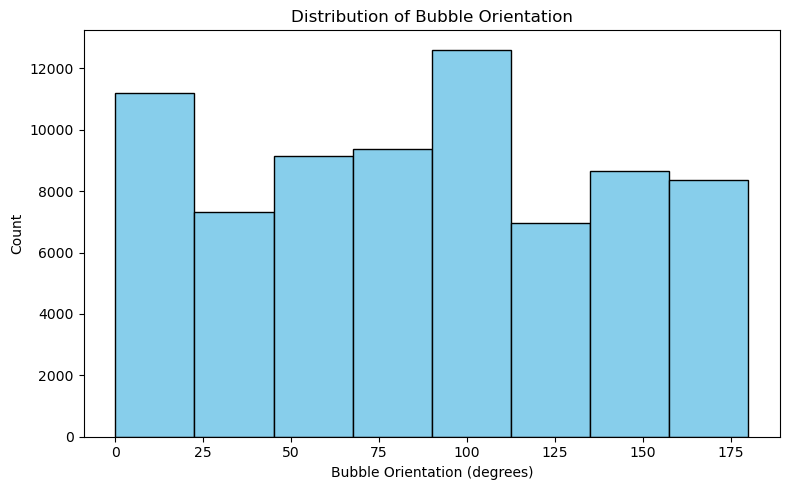

In [20]:
Q1 = full_bubble_df["orientation"].quantile(0.25)
Q3 = full_bubble_df["orientation"].quantile(0.75)
IQR = Q3 - Q1

# Define threshold (1.5×IQR is standard, 3×IQR is stricter)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered = full_bubble_df[(full_bubble_df["orientation"] >= lower_bound) & (full_bubble_df["orientation"] <= upper_bound)]

print(f"Removed {len(full_bubble_df) - len(filtered)} outliers")


#data = filtered
print(filtered["orientation"])
#bins = np.logspace(np.log10(filtered["orientation"].min()), np.log10(filtered["orientation"].max()), 10)
plt.figure(figsize=(8, 5))
plt.hist(filtered["orientation"], bins=8, color='skyblue', edgecolor='black')
plt.xlabel("Bubble Orientation (degrees)")
plt.ylabel("Count")
plt.title("Distribution of Bubble Orientation")
plt.tight_layout()
plt.savefig(f"{output_dir}/TotalBubbleOrientationHistogram.png", dpi=300, bbox_inches='tight')
plt.show()

Removed 5342 outliers
0        1.59
1        2.04
2        1.50
3        1.17
5        1.22
         ... 
73657    1.61
73658    3.26
73659    1.65
73660    3.03
73664    1.64
Name: elongation, Length: 68323, dtype: float64


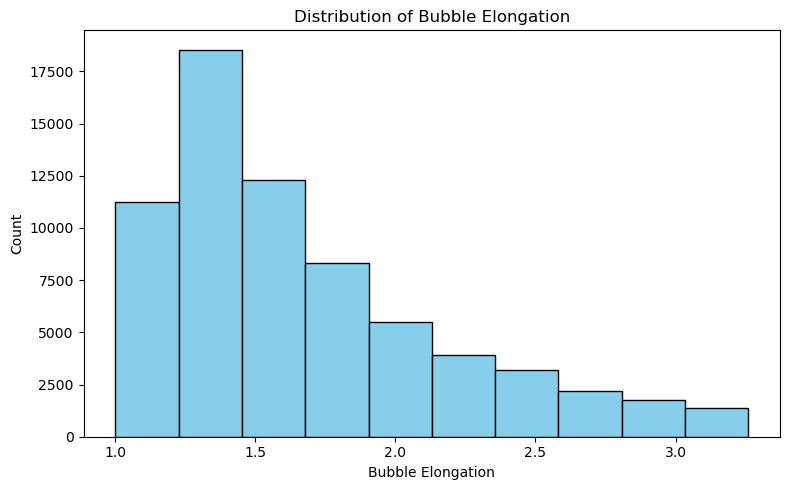

In [21]:
Q1 = full_bubble_df["elongation"].quantile(0.25)
Q3 = full_bubble_df["elongation"].quantile(0.75)
IQR = Q3 - Q1

# Define threshold (1.5×IQR is standard, 3×IQR is stricter)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered = full_bubble_df[(full_bubble_df["elongation"] >= lower_bound) & (full_bubble_df["elongation"] <= upper_bound)]

print(f"Removed {len(full_bubble_df) - len(filtered)} outliers")


#data = filtered
print(filtered["elongation"])
#bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 10)
plt.figure(figsize=(8, 5))
plt.hist(filtered["elongation"], bins=10, color='skyblue', edgecolor='black')
plt.xlabel("Bubble Elongation")
plt.ylabel("Count")
plt.title("Distribution of Bubble Elongation")
plt.tight_layout()
plt.savefig(f"{output_dir}/TotalBubbleElongationHistogram.png", dpi=300, bbox_inches='tight')
plt.show()

Removed 6236 outliers


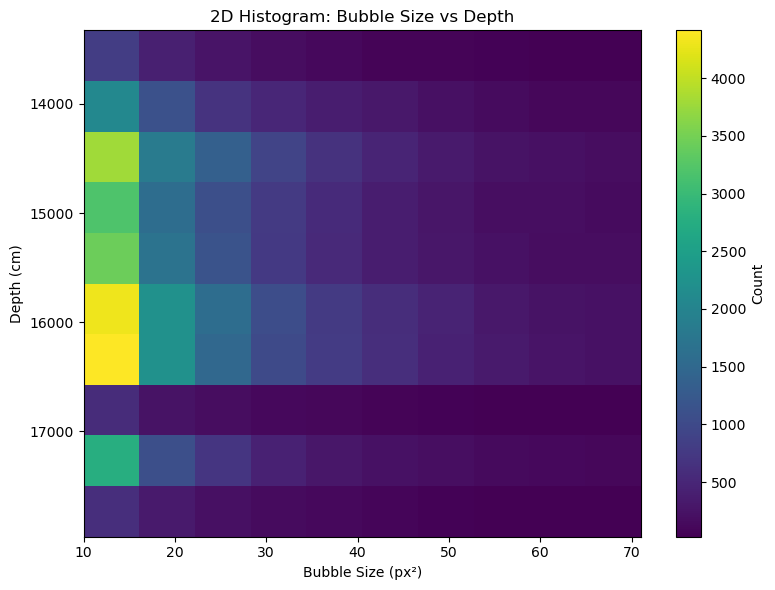

In [22]:
import numpy as np

Q1 = full_bubble_df["area"].quantile(0.25)
Q3 = full_bubble_df["area"].quantile(0.75)
IQR = Q3 - Q1

# Define threshold (1.5×IQR is standard, 3×IQR is stricter)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered = full_bubble_df[(full_bubble_df["area"] >= lower_bound) & (full_bubble_df["area"] <= upper_bound)]

print(f"Removed {len(full_bubble_df) - len(filtered)} outliers")

# Make 2D histogram
plt.figure(figsize=(8, 6))
h = plt.hist2d(
    filtered["area"],        # x-axis
    filtered["depth_cm"],    # y-axis
    bins=(10, 10),          # adjust resolution
    cmap="viridis"
)

plt.gca().invert_yaxis()
plt.colorbar(h[3], label="Count")
plt.ylabel("Depth (cm)")
plt.xlabel("Bubble Size (px²)")
plt.title("2D Histogram: Bubble Size vs Depth")
plt.tight_layout()
plt.savefig(f"{output_dir}/TotalBubbleSize2dHistogram.png", dpi=300, bbox_inches='tight')
plt.show()